# Chapter 5: Defending it in the room: what will they push on?

*Reading the memo aloud under challenge*

**Who needs the answer.** The committee in the room, each with a reason to push: the one who wants the higher score, the one who wants the smaller bill, and the one who wants to know what carries over.

**The questions on the way.** Does the memo fit in ninety seconds? What will each seat push on? What shape does a good answer take, and which number does it carry?

**What you will be able to do.** Time a memo against a ninety-second budget, map each likely push to its seat, and answer each with a number and the condition that would change the call.

**Search terms.** ML case interview, stakeholder pushback, walk me through a model you built

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10.5, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED, LILAC = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#CFC9EE"

def check(label, ok):
    """Print PASS or FAIL on its own line; a failed check never stops the notebook."""
    print(("PASS  " if ok else "FAIL  ") + label)

# Invented for teaching: 20 lapsed members of a gym in Indore and who came back after a call.
# Model A uses two columns (months since the last visit, visits in the last month); model B uses forty.
import numpy as np, pandas as pd
gym = pd.DataFrame({
    "member":  ["M07", "M12", "M03", "M15", "M01", "M19", "M09", "M05", "M18", "M11",
                "M02", "M14", "M06", "M20", "M08", "M16", "M04", "M13", "M10", "M17"],
    "plan":    ["student", "regular", "regular", "family", "student", "regular", "family", "regular", "student", "family",
                "regular", "regular", "family", "student", "regular", "family", "regular", "student", "regular", "family"],
    "score_A": [0.81, 0.74, 0.66, 0.58, 0.47, 0.41, 0.35, 0.29, 0.24, 0.20,
                0.17, 0.14, 0.11, 0.09, 0.07, 0.05, 0.04, 0.03, 0.02, 0.01],
    "score_B": [0.77, 0.52, 0.70, 0.61, 0.44, 0.40, 0.38, 0.33, 0.21, 0.19,
                0.25, 0.12, 0.10, 0.08, 0.15, 0.03, 0.18, 0.02, 0.04, 0.01],
    "came_back": [1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
})
CALL, MISS = 30, 900   # Rs per comeback call; Rs of margin lost per member who would have returned uncalled
print(f"{len(gym)} members (invented), {gym.came_back.sum()} came back; a call costs Rs {CALL}, a missed comeback Rs {MISS}")

memo = {
    "claim": "Call model A's top 6 lapsed members this week.",
    "evidence": "Last month 4 of the 5 who came back were in A's top 6, for Rs 180 of calls; calling nobody lost Rs 4,500. B's top 6 found the same 4.",
    "caveat": "20 members is a small sample, so one member moves the hit rate by 17 points; A scored one returner at 0.04.",
    "action": "Reception calls the 6 by Friday. If fewer than 2 of 6 return two weeks running, we pause and rescore.",
    "my choice": "I kept A over B because they tie on returners found and A runs on two columns the desk can check.",
}
WPM = 140   # an assumed speaking pace; time yourself once and replace it
words = {part: len(text.split()) for part, text in memo.items()}
seconds = {part: round(w / WPM * 60) for part, w in words.items()}
pd.DataFrame({"words": words, "seconds": seconds})

20 members (invented), 5 came back; a call costs Rs 30, a missed comeback Rs 900


,words,seconds
claim,9,4
evidence,31,13
caveat,22,9
action,20,9
my choice,21,9


## Does it fit in ninety seconds?

The interview asks for a model you built in about ninety seconds; the committee gives the same. At 140 words a minute, ninety seconds holds about 210 words.

**Predict before you run.** The owner says "B's score is 0.05 higher, use B". What is the strongest one-line answer? a) "A is better, trust me"; b) "AUC measures ranking quality across all pairs"; c) "Both find the same 4 returners in 6 calls, so the gap is worth Rs 0 this week; B ships if it finds more on next month's list"; d) "We can use both".

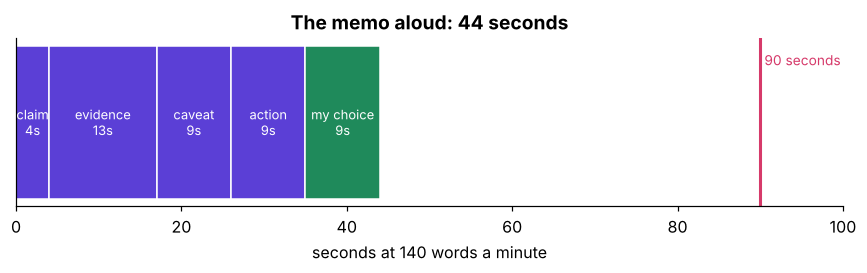

In [2]:
fig, ax = plt.subplots(figsize=(8, 2.6))
left = 0
for part, s in seconds.items():
    ax.barh(0, s, left=left, color=VIOLET if part != "my choice" else GREEN, edgecolor="white")
    ax.text(left + s / 2, 0, f"{part}\n{s}s", ha="center", va="center", color="white", fontsize=8.5)
    left += s
ax.axvline(90, color=ROSE, lw=2); ax.text(90.5, 0.3, "90 seconds", color=ROSE, fontsize=9)
ax.set_xlim(0, 100); ax.set_yticks([]); ax.set_xlabel("seconds at 140 words a minute")
ax.set_title(f"The memo aloud: {sum(seconds.values())} seconds")
plt.tight_layout(); plt.show()

In [3]:
from sklearn.metrics import roc_auc_score
aA, aB = roc_auc_score(gym.came_back, gym.score_A), roc_auc_score(gym.came_back, gym.score_B)
top6 = lambda col: int(gym.sort_values(col, ascending=False).head(6).came_back.sum())
print(f"AUC A {aA:.3f}, B {aB:.3f}: B ranks {round((aB - aA) * 75)} more pairs right, out of 75")
print(f"returners in the top 6: A {top6('score_A')}, B {top6('score_B')}; rupee gap this week Rs {(top6('score_A') - top6('score_B')) * 930}")

AUC A 0.800, B 0.853: B ranks 4 more pairs right, out of 75
returners in the top 6: A 4, B 4; rupee gap this week Rs 0


**What happened.** The answer is c. The AUC gap is four pairs out of 75, and both models put the same four returners in the top six, so this week the gap is worth nothing in rupees. The answer names the number, the reason, and the condition that would flip it. Option b explains the metric to someone who asked for a decision.

In [4]:
challenge = pd.DataFrame([
    ("growth lead", "Use the higher-scoring model.", "Same 4 returners in 6 calls; B ships if it finds more next month."),
    ("finance", "Can the bill be smaller?", "Rs 180 of calls against Rs 4,500 lost by calling nobody; 6 calls is the budget."),
    ("product manager", "What does a member experience?", "One call with one offer; nobody is called twice in 30 days."),
    ("QA", "How do we know the cut is live?", "Each Friday, check that exactly 6 names were called and log the 6 scores."),
    ("risk head", "What carries over to lending?", "The split, the bill and the rule; the cut moves to 0.95 on P(repay)."),
], columns=["seat", "push", "answer shape"])
challenge["carries a number"] = challenge["answer shape"].str.contains(r"\d")
print(challenge.to_string(index=False))
check("every answer carries a number", challenge["carries a number"].all())
check("the spoken memo fits in ninety seconds", sum(seconds.values()) <= 90)

           seat                            push                                                                    answer shape  carries a number
    growth lead   Use the higher-scoring model.               Same 4 returners in 6 calls; B ships if it finds more next month.              True
        finance        Can the bill be smaller? Rs 180 of calls against Rs 4,500 lost by calling nobody; 6 calls is the budget.              True
product manager  What does a member experience?                     One call with one offer; nobody is called twice in 30 days.              True
             QA How do we know the cut is live?       Each Friday, check that exactly 6 names were called and log the 6 scores.              True
      risk head   What carries over to lending?            The split, the bill and the rule; the cut moves to 0.95 on P(repay).              True
PASS  every answer carries a number
PASS  the spoken memo fits in ninety seconds


## What did this chapter establish?

| Question | Answer |
|---|---|
| The ninety-second shape | Claim, evidence, caveat, action, and one choice you made yourself |
| The higher-score push | Size the gap in members and rupees, then say what would flip it |
| A good answer | A number, the reason, the condition that changes the call |

The case chapters now build the bank's version of this memo from the week's own numbers.